# Practical 4 — N-Queens using Backtracking

**Subject:** Design and Analysis of Algorithms (410241)  
**Class:** B.E. Computer Engineering, Semester I  
**Lab:** Laboratory Practice III (410246)

---

## 1. Aim

Design an $N \times N$ chessboard with the **first queen already placed**, and
use backtracking to place the remaining $N-1$ queens so that no two queens
attack each other.

## 2. Problem statement

Place $N$ queens on an $N \times N$ board such that:

- every row contains exactly one queen,
- every column contains exactly one queen,
- no two queens share a diagonal.

The first queen is fixed at row `0`, column `first_col`. Generate one valid
board (and optionally all valid boards), and count the solutions.

## 3. Objectives

- Understand the backtracking design technique.
- Use constraint sets to check column and diagonal conflicts in $O(1)$ time.
- Prune partial solutions as soon as they become invalid.
- Analyse the worst-case and practical complexity of backtracking.

## 4. Theory

### 4.1 Constraints

Two queens at $(r_1,c_1)$ and $(r_2,c_2)$ attack each other if:

- they are in the same row: $r_1=r_2$,
- they are in the same column: $c_1=c_2$,
- they are on the same diagonal: $|r_1-r_2|=|c_1-c_2|$.

Because we place exactly one queen per row, the row constraint is automatic.
We only need to track:

- **columns** already occupied,
- **main diagonals**, identified by $r-c$,
- **anti-diagonals**, identified by $r+c$.

For a queen at $(r,c)$:

- the column is `c`,
- the main diagonal is `r - c`,
- the anti-diagonal is `r + c`.

### 4.2 Backtracking

```text
PLACE(row)
    if row == N
        record a solution
        return
    for col = 0 to N-1
        if col, row-col and row+col are all free
            put a queen at (row, col)
            mark column and diagonals
            PLACE(row + 1)
            remove the queen and unmark      // backtrack
```

The first queen is placed before the recursion starts. The recursion then
begins at row 1.

### 4.3 Complexity

In the worst case the search tree has about $N!$ nodes, so the time complexity
is $O(N!)$. The constraint checks prune most branches, so the practical
running time is much smaller. The recursion depth and the board use $O(N)$
space.

The number of solutions grows quickly:

| N | 1 | 2 | 3 | 4 | 5 | 6 | 7 | 8 |
|---|---|---|---|---|---|---|---|---|
| Solutions | 1 | 0 | 0 | 2 | 10 | 4 | 40 | 92 |

In [1]:
import matplotlib.pyplot as plt
import pandas as pd

plt.style.use("seaborn-v0_8-whitegrid")

In [2]:
def solve_n_queens(n: int, first_col: int = 0, find_all: bool = False):
    """Solve N-Queens with the first queen fixed at (0, first_col).

    Returns
    -------
    solutions : list[list[int]]
        Each solution is a list ``board`` where ``board[row] = column``.
    nodes : int
        Number of recursive calls made by the backtracking search.
    """
    if n < 1:
        raise ValueError("N must be a positive integer")
    if not 0 <= first_col < n:
        raise ValueError(f"first_col must be between 0 and {n - 1}")

    board = [-1] * n
    board[0] = first_col

    # Constraint sets for O(1) conflict checks.
    occupied_columns = {first_col}
    occupied_main_diagonals = {0 - first_col}   # r - c
    occupied_anti_diagonals = {0 + first_col}   # r + c

    solutions: list[list[int]] = []
    nodes = 0

    def backtrack(row: int) -> bool:
        """Place queens from ``row`` onwards. Return True to stop early."""
        nonlocal nodes
        nodes += 1

        if row == n:
            solutions.append(board.copy())
            return not find_all

        for col in range(n):
            main_diagonal = row - col
            anti_diagonal = row + col

            if (
                col in occupied_columns
                or main_diagonal in occupied_main_diagonals
                or anti_diagonal in occupied_anti_diagonals
            ):
                continue

            # Choose.
            board[row] = col
            occupied_columns.add(col)
            occupied_main_diagonals.add(main_diagonal)
            occupied_anti_diagonals.add(anti_diagonal)

            # Explore.
            if backtrack(row + 1):
                return True

            # Un-choose (backtrack).
            occupied_columns.remove(col)
            occupied_main_diagonals.remove(main_diagonal)
            occupied_anti_diagonals.remove(anti_diagonal)
            board[row] = -1

        return False

    backtrack(1)
    return solutions, nodes


def board_as_text(board: list[int]) -> str:
    """Render a board as a grid of Q and . characters."""
    n = len(board)
    lines = []
    for row in range(n):
        lines.append(" ".join("Q" if board[row] == col else "." for col in range(n)))
    return "\n".join(lines)

In [3]:
# Solve the standard 8-queens problem with the first queen at (0, 0).
n = 8
solutions, nodes = solve_n_queens(n, first_col=0, find_all=True)

print(f"Board size       : {n} x {n}")
print(f"First queen      : row 0, column 0")
print(f"Solutions found  : {len(solutions)}")
print(f"Recursive calls  : {nodes}")
print("\nFirst solution:")
print(board_as_text(solutions[0]))

Board size       : 8 x 8
First queen      : row 0, column 0
Solutions found  : 4
Recursive calls  : 227

First solution:
Q . . . . . . .
. . . . Q . . .
. . . . . . . Q
. . . . . Q . .
. . Q . . . . .
. . . . . . Q .
. Q . . . . . .
. . . Q . . . .


In [4]:
# Display all solutions found for the fixed first queen.
# (There are 4 for this configuration.)
for number, solution in enumerate(solutions, start=1):
    columns = [column + 1 for column in solution]
    print(f"Solution {number}: queen columns by row = {columns}")
    print(board_as_text(solution))
    print()

Solution 1: queen columns by row = [1, 5, 8, 6, 3, 7, 2, 4]
Q . . . . . . .
. . . . Q . . .
. . . . . . . Q
. . . . . Q . .
. . Q . . . . .
. . . . . . Q .
. Q . . . . . .
. . . Q . . . .

Solution 2: queen columns by row = [1, 6, 8, 3, 7, 4, 2, 5]
Q . . . . . . .
. . . . . Q . .
. . . . . . . Q
. . Q . . . . .
. . . . . . Q .
. . . Q . . . .
. Q . . . . . .
. . . . Q . . .

Solution 3: queen columns by row = [1, 7, 4, 6, 8, 2, 5, 3]
Q . . . . . . .
. . . . . . Q .
. . . Q . . . .
. . . . . Q . .
. . . . . . . Q
. Q . . . . . .
. . . . Q . . .
. . Q . . . . .

Solution 4: queen columns by row = [1, 7, 5, 8, 2, 4, 6, 3]
Q . . . . . . .
. . . . . . Q .
. . . . Q . . .
. . . . . . . Q
. Q . . . . . .
. . . Q . . . .
. . . . . Q . .
. . Q . . . . .



The four solutions are distinct, but they are related by the symmetry of the
square board. Fixing the first queen removes the translations/reflections that
would otherwise produce duplicate-looking boards.

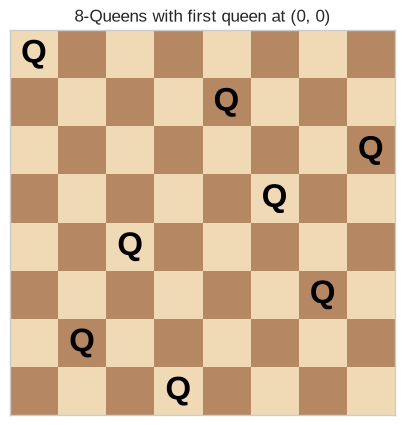

In [5]:
# Visualise the first solution as a chessboard.
def draw_board(board: list[int], title: str = "N-Queens solution") -> None:
    n = len(board)
    figure, axis = plt.subplots(figsize=(5, 5))
    for row in range(n):
        for col in range(n):
            colour = "#f0d9b5" if (row + col) % 2 == 0 else "#b58863"
            axis.add_patch(
                plt.Rectangle((col, n - 1 - row), 1, 1, facecolor=colour)
            )
    for row, col in enumerate(board):
        axis.text(
            col + 0.5,
            n - 1 - row + 0.5,
            "Q",
            ha="center",
            va="center",
            fontsize=24,
            fontweight="bold",
            color="black",
        )
    axis.set_xlim(0, n)
    axis.set_ylim(0, n)
    axis.set_aspect("equal")
    axis.set_xticks([])
    axis.set_yticks([])
    axis.set_title(title)
    plt.show()


draw_board(solutions[0], "8-Queens with first queen at (0, 0)")

In [6]:
# Count solutions for different board sizes and first-queen columns.
count_rows = []
for size in range(4, 9):
    row = {"N": size}
    for first_column in range(size):
        found, _ = solve_n_queens(size, first_col=first_column, find_all=True)
        row[f"col {first_column}"] = len(found)
    row["total"] = sum(row[f"col {c}"] for c in range(size))
    count_rows.append(row)

count_table = pd.DataFrame(count_rows).set_index("N")
count_table = count_table.apply(
    lambda column: column.map(lambda value: "" if pd.isna(value) else int(value))
)
count_table

,col 0,col 1,col 2,col 3,total,col 4,col 5,col 6,col 7
N,,,,,,,,,
4,0,1,1,0,2,,,,
5,2,2,2,2,10,2,,,
6,0,1,1,1,4,1,0,,
7,4,7,6,6,40,6,7,4,
8,4,8,16,18,92,18,16,8,4


### Why some entries are zero

For $N=4$ and $N=6$, a queen in a corner leaves no valid completion. The table
also shows the symmetry of the board: the counts for column `c` and column
`N-1-c` are equal, because reflecting the board left-to-right preserves all
constraints. The total in the last column is the well-known number of
$N$-queens solutions (2, 10, 4, 40, 92 for $N=4,\dots,8$).

### Test cases

1. $N=1$: one queen at `(0,0)`, one solution.
2. $N=2,3$: no solution.
3. Invalid first column: a `ValueError`.
4. A large board: the search still terminates quickly for $N=8$.

In [7]:
# Edge cases and validation.
for size, first_column in [(1, 0), (2, 0), (3, 0), (4, 1)]:
    found, calls = solve_n_queens(size, first_col=first_column, find_all=True)
    print(
        f"N={size}, first_col={first_column}: "
        f"{len(found)} solution(s), {calls} recursive calls"
    )

for bad_size, bad_column in [(0, 0), (4, 4), (4, -1)]:
    try:
        solve_n_queens(bad_size, first_col=bad_column)
    except ValueError as error:
        print(f"ValueError: {error}")

assert len(solve_n_queens(1)[0]) == 1
assert len(solve_n_queens(2, find_all=True)[0]) == 0
assert len(solve_n_queens(3, find_all=True)[0]) == 0
print("\nAll validation checks passed ✓")

N=1, first_col=0: 1 solution(s), 1 recursive calls
N=2, first_col=0: 0 solution(s), 1 recursive calls
N=3, first_col=0: 0 solution(s), 2 recursive calls
N=4, first_col=1: 1 solution(s), 4 recursive calls
ValueError: N must be a positive integer
ValueError: first_col must be between 0 and 3
ValueError: first_col must be between 0 and 3

All validation checks passed ✓


In [8]:
# Compare the number of solutions and the search effort as N grows.
growth_rows = []
for size in range(4, 11):
    found, calls = solve_n_queens(size, first_col=0, find_all=True)
    growth_rows.append(
        {
            "N": size,
            "solutions (first_col=0)": len(found),
            "recursive calls": calls,
        }
    )

growth = pd.DataFrame(growth_rows)
growth

,N,solutions (first_col=0),recursive calls
0,4,0,4
1,5,2,11
2,6,0,22
3,7,4,72
4,8,4,227
5,9,28,833
6,10,64,3203


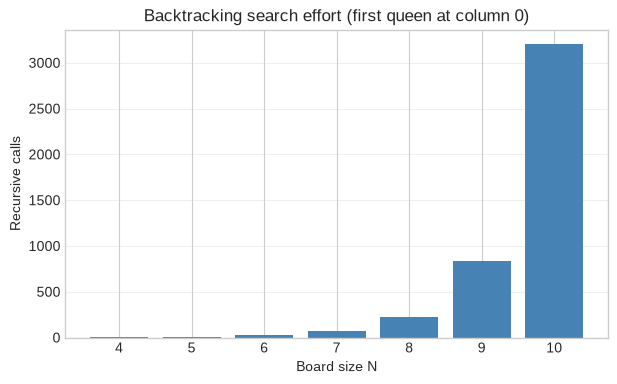

In [9]:
plt.figure(figsize=(7, 4))
plt.bar(growth["N"], growth["recursive calls"], color="steelblue")
plt.xlabel("Board size N")
plt.ylabel("Recursive calls")
plt.title("Backtracking search effort (first queen at column 0)")
plt.xticks(growth["N"])
plt.grid(axis="y", alpha=0.3)
plt.show()

In [10]:
# ============================================================================
# DETAILED OUTPUT EXPLANATION
# ============================================================================
import math

print("DETAILED OUTPUT EXPLANATION - DAA Practical 4 (N-Queens)")
print("=" * 78)
print(
    "The first queen is fixed at row 0, column 0 for the 8x8 run. Backtracking\n"
    "then places one queen in each remaining row. The report explains the\n"
    "solution count, the search effort, the symmetry and the validation cases."
)

print("\n1. 8-QUEENS RESULT WITH FIRST QUEEN AT (0, 0)")
print("-" * 78)
print(f"Board size          : {n} x {n}")
print(f"Solutions found     : {len(solutions)}")
print(f"Recursive calls     : {nodes}")
print(f"Queen columns by row: {[column + 1 for column in solutions[0]]}")
print("First solution:")
print(board_as_text(solutions[0]))
print("Interpretation: each number is the 1-based column of the queen in that")
print("row. No two numbers repeat (column constraint), and no two queens share")
print("a diagonal because the solver only places a queen when r-c and r+c are")
print("both free. This is one valid completion of the fixed first queen.")

print("\n2. ALL FOUR SOLUTIONS FOR THIS FIXED FIRST QUEEN")
print("-" * 78)
for number, solution in enumerate(solutions, start=1):
    print(f"  Solution {number}: {[column + 1 for column in solution]}")
print("The four boards are distinct solutions of the full 8-queens problem.")
print("There are 92 solutions in total when the first queen is allowed in any")
print("column; fixing her at column 0 keeps only the completions compatible")
print("with that choice.")

print("\n3. SEARCH EFFORT AND GROWTH")
print("-" * 78)
print("Growth for the fixed first queen at column 0:")
for _, row in growth.iterrows():
    size = int(row["N"])
    estimate = math.factorial(size)
    print(
        f"  N={size:2d}: solutions={int(row['solutions (first_col=0)']):3d}, "
        f"calls={int(row['recursive calls']):7d}, N!={estimate:,}"
    )
print("The number of recursive calls is much smaller than N! on these boards.")
print("That gap is the effect of pruning: a partial board is abandoned as soon")
print("as the next queen has no legal column. The worst-case bound O(N!) still")
print("describes the search tree, but the constraint checks make the practical")
print("search much smaller.")

print("\n4. SOLUTION COUNTS BY BOARD SIZE AND FIRST COLUMN")
print("-" * 78)
for size in count_table.index:
    row = count_table.loc[size]
    total = int(row["total"])
    print(f"  N={int(size)}: total solutions={total}")
print("Known totals: N=4 -> 2, N=5 -> 10, N=6 -> 4, N=7 -> 40, N=8 -> 92.")
print("The zero entries at N=4 and N=6 for some first columns are real: a queen")
print("in that column leaves no valid completion. The table is left-right")
print("symmetric because reflecting the board preserves all constraints.")

print("\n5. EDGE CASES AND VALIDATION")
print("-" * 78)
for size, first_column in [(1, 0), (2, 0), (3, 0), (4, 1)]:
    found, calls = solve_n_queens(size, first_col=first_column, find_all=True)
    print(
        f"  N={size}, first_col={first_column}: "
        f"{len(found)} solution(s), {calls} recursive calls"
    )
for bad_size, bad_column in [(0, 0), (4, 4), (4, -1)]:
    try:
        solve_n_queens(bad_size, first_col=bad_column)
    except ValueError as error:
        print(f"  ValueError correctly raised: {error}")
print("N=1 has one solution. N=2 and N=3 have none. Invalid board sizes and")
print("columns are rejected before the search starts.")

print("\n6. COMPLEXITY TAKEAWAY")
print("-" * 78)
print("Time  : O(N!) in the worst case, with pruning usually much smaller")
print("Space : O(N) for the board, three constraint sets and recursion stack")
print("Storing all S solutions adds O(N*S) space.")
print("The key idea is to check columns and diagonals in O(1) instead of")
print("rescanning the board for every candidate queen.")

DETAILED OUTPUT EXPLANATION - DAA Practical 4 (N-Queens)
The first queen is fixed at row 0, column 0 for the 8x8 run. Backtracking
then places one queen in each remaining row. The report explains the
solution count, the search effort, the symmetry and the validation cases.

1. 8-QUEENS RESULT WITH FIRST QUEEN AT (0, 0)
------------------------------------------------------------------------------
Board size          : 8 x 8
Solutions found     : 4
Recursive calls     : 227
Queen columns by row: [1, 5, 8, 6, 3, 7, 2, 4]
First solution:
Q . . . . . . .
. . . . Q . . .
. . . . . . . Q
. . . . . Q . .
. . Q . . . . .
. . . . . . Q .
. Q . . . . . .
. . . Q . . . .
Interpretation: each number is the 1-based column of the queen in that
row. No two numbers repeat (column constraint), and no two queens share
a diagonal because the solver only places a queen when r-c and r+c are
both free. This is one valid completion of the fixed first queen.

2. ALL FOUR SOLUTIONS FOR THIS FIXED FIRST QUEEN
-

### Observations

1. The first queen is placed before the search begins; the recursion only
   handles rows `1 ... N-1`. This satisfies the requirement of a pre-placed
   first queen.
2. The three sets (`columns`, `r-c`, `r+c`) make each conflict check $O(1)$.
   Without them, checking a partial board would take $O(N)$ per candidate.
3. Backtracking is a depth-first search with pruning. A partial board is
   abandoned as soon as a queen cannot be placed in the current row.
4. The number of recursive calls is much smaller than $N!$ for $N=8$, showing
   the effect of pruning. The worst-case bound is still $O(N!)$.
5. The board is stored as a one-dimensional list: `board[row] = column`. This
   uses $O(N)$ space instead of an $N \times N$ matrix.

### Complexity analysis

- **Time:** $O(N!)$ in the worst case; the exact number of nodes depends on
  $N$ and on the fixed first column.
- **Space:** $O(N)$ for the board, the three constraint sets and the recursion
  stack. Storing all solutions adds $O(N \cdot S)$ for $S$ solutions.

## 5. Conclusion

We designed an $N$-Queens solver in which the first queen is placed at a
chosen column. Backtracking places the remaining queens row by row, using
column and diagonal sets for constant-time conflict checks. The program finds
all valid boards for $N=8$ and handles impossible boards and invalid input
gracefully. The experiment demonstrates how pruning turns an exponential
search into a practical algorithm for small $N$.

## 6. Viva questions

| Question | Short answer |
|---|---|
| What is backtracking? | A depth-first search that abandons a partial solution as soon as it cannot be completed. |
| Why is one queen placed per row? | It removes the row-conflict check and reduces the branching factor. |
| How is a diagonal identified? | Main diagonal: $r-c$; anti-diagonal: $r+c$. |
| What is the worst-case time complexity? | $O(N!)$. |
| What is the space complexity? | $O(N)$ for the board and recursion stack (excluding stored solutions). |
| Why are constraint sets used? | They make conflict checks $O(1)$ instead of scanning the board. |
| How many solutions does 8-Queens have? | 92 in total; with the first queen fixed at a particular column, fewer. |
| What happens if the first queen is in a corner? | For some $N$ (e.g. $N=4$), no completion exists, so the algorithm correctly returns no solution. |